In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "6"
import torch
from data.batter import BatterDataset
# from models_vit import VisionTransformer
from models_vit import vit_batter_patch16 as vit
from util import misc
from torchvision import transforms
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import torch
from torch import nn
import matplotlib
import glob
import scipy.io as sio

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']

def draw_plot(x, y, x_label="True Values", y_label="Predictions", result="picture/tt.jpg", 
              title=None):
    if not os.path.exists(os.path.dirname(result)):
        os.makedirs(os.path.dirname(result))
    # 绘制预测值和真实值的对比图（同一x, y轴）
    plt.figure(figsize=(12, 6))
    plt.plot(x, label=x_label, color='blue', linewidth=2)
    plt.plot(y, label=y_label, color='orange', linestyle='--', linewidth=2)

    plt.xlabel('Sample Index')
    plt.ylabel('Value')
    plt.legend(loc='upper left')

    # 添加R²分数
    r2 = r2_score(x, y)
    plt.text(0.95, 0.95, f'R² = {r2:.4f}', transform=plt.gca().transAxes, 
            horizontalalignment='right', verticalalignment='top')

    plt.grid(True)
    plt.savefig(result, dpi=300)

    # 计算和打印评估指标
    mse = np.mean((x - y) ** 2)
    mae = np.mean(np.abs(x - y))
    
    print(f'Mean Squared Error: {mse:.4f}')
    print(f'Mean Absolute Error: {mae:.4f}')
    print(f'R² Score: {r2:.4f}')
    
    
def prepapre_model(ckpt):
    checkpoint = torch.load(ckpt, map_location='cuda')
    vit_model = vit(img_size=128, in_chans=6)
    vit_model.load_state_dict(checkpoint['model'], strict=False)
    if torch.cuda.is_available():
        vit_model = vit_model.to('cuda')
    else:
        vit_model = vit_model.to('cpu')
    return vit_model

def prepare_data(data_path, batter):
    transform_train = transforms.Compose([
                transforms.ToTensor(),
                ])

    transform_val = transforms.Compose([
                transforms.ToTensor(),
                ])

    dataset_train = BatterDataset(
            data_path=data_path,
            transform=transform_train,
            is_train=True,
            batter=batter
        )
        

    dataset_val = BatterDataset(
            data_path=data_path,
            transform=transform_val,
            is_train=False,
            batter=batter
        )
    
    train_set = set(dataset_train.target_list)
    val_set = set(dataset_val.target_list)
    
    inter = train_set.intersection(val_set)
    if len(inter) > 0:
        print(f"Intersection between train and val sets: {inter}")
    else:
        print("No intersection between train and val sets.")
                
    num_tasks = misc.get_world_size()
    global_rank = misc.get_rank()
    sampler_train = torch.utils.data.DistributedSampler(
        dataset_train, num_replicas=num_tasks, rank=global_rank, shuffle=True
    )

    sampler_val = torch.utils.data.SequentialSampler(dataset_val)

    data_loader_train = torch.utils.data.DataLoader(
            dataset_train, sampler=sampler_train,
            batch_size=5,
            num_workers=2,
            pin_memory=True,
            drop_last=True,
        )
    data_loader_val = torch.utils.data.DataLoader(
            dataset_val, sampler=sampler_val,
            batch_size=1,
            num_workers=1,
            pin_memory=True,
            drop_last=False,
        )
    
    return data_loader_train, data_loader_val



/path/to/conda/envs/mae/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
weight_path = f"/path/to/mae/batter_output/mae_train_final/checkpoint-399.pth"
fixed_path = "/path/to/mae/data/fixed_data_final"
result_path = "feature_extract_result"
os.makedirs(result_path, exist_ok=True)
# battery = "NMC"  # or "LCO"
battery_data = glob.glob(os.path.join(fixed_path, f"*.mat"))
battery_data.sort()

In [ ]:

transform_en = transforms.Compose([
    transforms.ToTensor(),
])
encoder = prepapre_model(ckpt=weight_path) 
feature_dict = {}
for param in encoder.parameters():
    param.requires_grad = False
encoder.cuda()
encoder.eval()


/tmp/ipykernel_2247532/1979751681.py:53: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(ckpt, map_location='cuda')


VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(6, 1024, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
    (1): Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwi

In [12]:
with torch.no_grad():
    for i, data_path in enumerate(battery_data):
        data = sio.loadmat(data_path)
        images = transform_en(data['data']).unsqueeze(0)  # Add batch dimension
        labels = data['ah'].reshape(-1)[0]
        images = images.float().to('cuda')
        features = encoder(images)
        features = features.cpu().numpy().reshape(-1)
        feature_with_label = np.append(features, labels)
        name = os.path.basename(data_path)
        np.save(os.path.join(result_path, f"{name}.npy"), feature_with_label)


In [17]:
weight_s = glob.glob(os.path.join("/path/to/mae/batter_output", "**/*.pth"))
for weight in weight_s:
    if "399" in weight:
        os.rename(weight, weight.replace("399", "final"))
    if "399" not in weight and "final" not in weight:
        os.remove(weight)
  

In [5]:
for k, v in feature_dict.items():
    print(f"Feature for {k}: {v.shape}")
    
    # sio.savemat(k.replace('.mat', '_features.mat'), {'features': v})

Feature for 0.1166: (1024,)
Feature for 0.2332: (1024,)
Feature for 0.3498: (1024,)
Feature for 0.4664: (1024,)
Feature for 0.6996: (1024,)


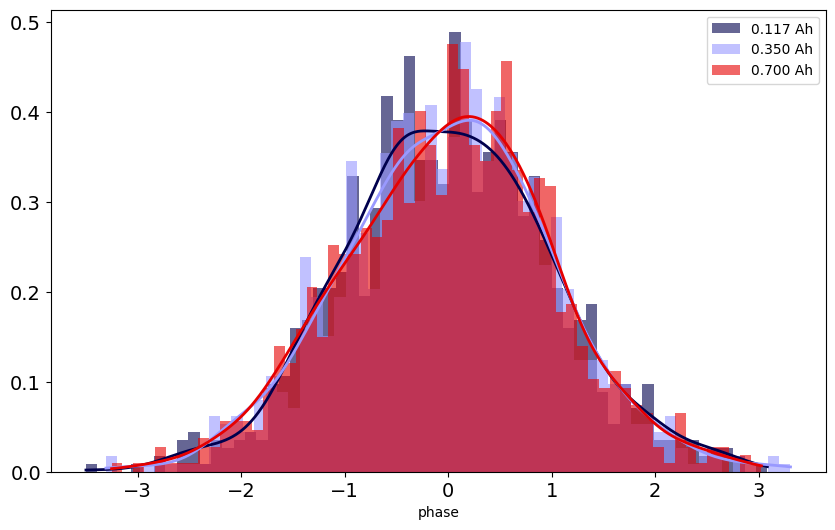

In [21]:
from scipy.stats import gaussian_kde

# 绘制每个特征的直方图并赋予不同的颜色
plt.figure(figsize=(10, 6))
colors = plt.cm.seismic
for i, (key, feature) in enumerate(feature_dict.items()):
    if round(key, 3) in [0.233, 0.466]:
        continue
    label = key
    # 绘制直方图
    plt.hist(feature, bins=60, color=colors(i / len(feature_dict)), alpha=0.6, label=f'{label:.3f} Ah', density=True)
    
    # 计算核密度估计并绘制拟合曲线
    kde = gaussian_kde(feature)
    x_vals = np.linspace(min(feature), max(feature), 1000)
    plt.plot(x_vals, kde(x_vals), color=colors(i / len(feature_dict)), linewidth=2)

plt.xlabel('phase')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(loc='upper right')
plt.show()

In [49]:
camps = ['flag', 'prism', 'Pastel1', 'Spectral', 'coolwarm', 'viridis', 'plasma', 'inferno', 'magma', 'cividis']
result_dir = "heat_picture"
os.makedirs(result_dir, exist_ok=True)
for i in camps:
    result_path = f"heat_picture/feature_heatmap_{i}.jpg"
    for feature in feature_dict.values():
        # 绘制热图
        reshaped_feature = feature.reshape((int(len(feature)**0.5), -1))  # 假设可以重塑为方阵
        plt.figure(figsize=(5, 5))
        plt.imshow(reshaped_feature, aspect='auto', cmap=i)
    # plt.colorbar(label="Value")
    # plt.title("Feature Heatmap")
        plt.axis('off')
        plt.savefig(result_path, dpi=300, bbox_inches='tight')
        plt.close()
        break